In [1]:
import pandas as pd
import numpy as np

df_daily_raw = pd.read_csv('BICC_Daily_Markets_Anon.csv')
df_weekly_raw = pd.read_csv('BICC_Weekly_Macro_Anon.csv')
df_monthly_raw = pd.read_csv('BICC_Monthly_Macro_Anon.csv')

df_daily_raw['Date'] = pd.to_datetime(df_daily_raw['Date'].astype(str).str.strip())
df_weekly_raw['Date'] = pd.to_datetime(df_weekly_raw['Date'].astype(str).str.strip())
df_monthly_raw['Date'] = pd.to_datetime(df_monthly_raw['Date'].astype(str).str.strip())

df_daily = df_daily_raw.sort_values('Date').reset_index(drop=True)
df_weekly = df_weekly_raw.sort_values('Date').reset_index(drop=True)
df_monthly = df_monthly_raw.sort_values('Date').reset_index(drop=True)

# Scalanie danych dziennych, tygodniowych i miesiecznych (merge_asof)
df_hybrid = pd.merge_asof(df_daily, df_weekly, on='Date', direction='backward')
df_final = pd.merge_asof(df_hybrid, df_monthly, on='Date', direction='backward')

# Uzupelnienie brakow danych
df_final = df_final.bfill().ffill()

chosen_columns = [
    'Date',
    'Target_Asset_Close',
    'Risk_Index_Close',
    'Supply_Chain_Index_Close',
    'Macro_Stress_RegionA',
    'Safe_Haven_Metal_Close'
]

df_model = df_final[chosen_columns].copy()


In [2]:
from IPython.display import HTML, display

selected_cols = [
    'Target_Asset_Close',
    'Risk_Index_Close',
    'Supply_Chain_Index_Close',
    'Safe_Haven_Metal_Close',
    'Macro_Stress_RegionA'
]

# Statystyki opisowe i wspolczynnik zmiennosci
df_stats = df_model[selected_cols].describe().T[['mean', 'min', 'max']]
df_stats['Współczynnik Zmienności'] = df_model[selected_cols].std() / df_model[selected_cols].mean()
df_stats.columns = ['Wartość Średnia', 'Minimum (Min)', 'Maksimum (Max)', 'Współczynnik Zmienności']

df_stats_rounded = df_stats.round(2)
display(HTML(df_stats_rounded.to_html(border=1)))


,Wartość Średnia,Minimum (Min),Maksimum (Max),Współczynnik Zmienności
Target_Asset_Close,1.11,0.96,1.23,0.05
Risk_Index_Close,20.99,11.86,82.69,0.38
Supply_Chain_Index_Close,1786.57,393.00,5650.00,0.46
Safe_Haven_Metal_Close,2189.87,1477.30,4529.10,0.29
Macro_Stress_RegionA,-0.33,-0.98,5.67,-2.21


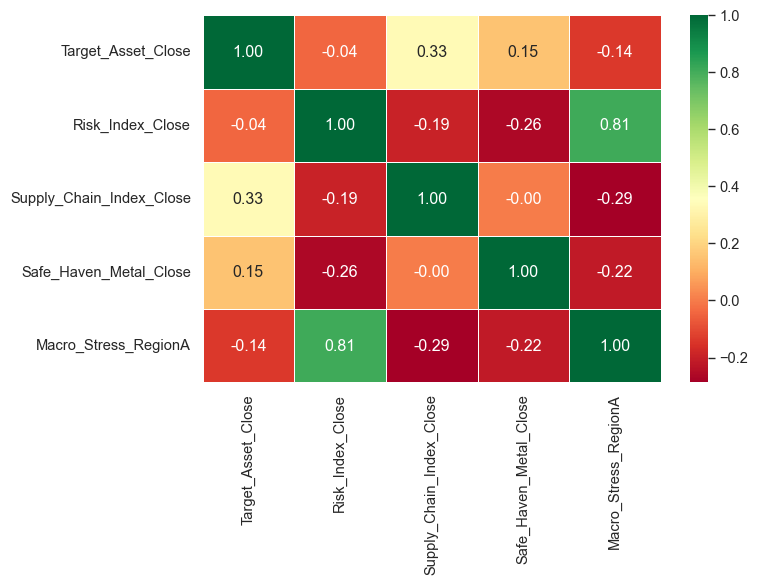

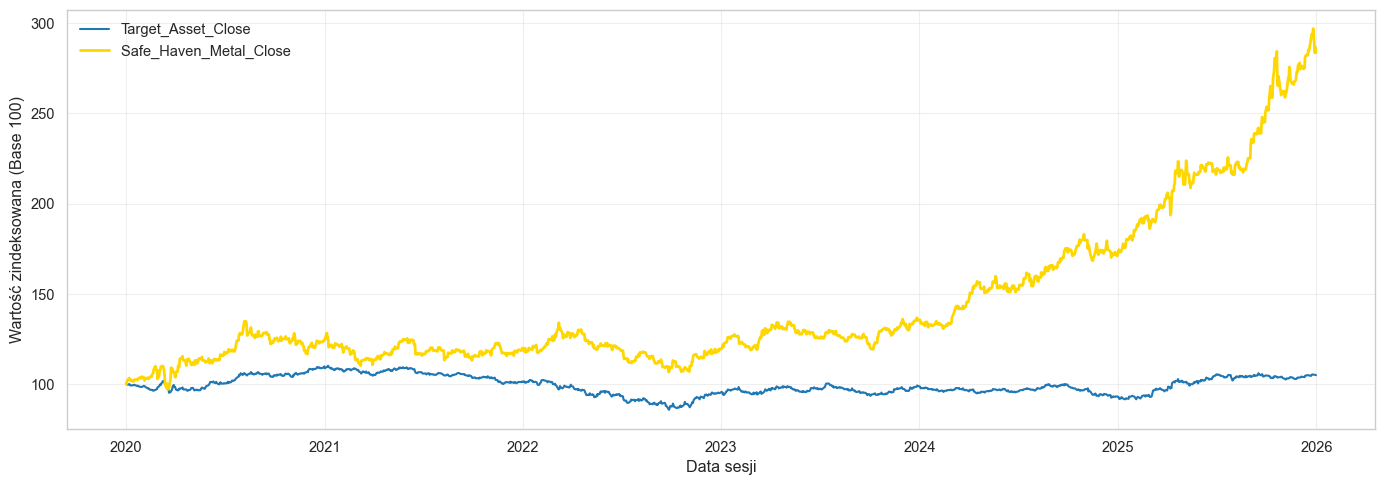

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context("paper", font_scale=1.2)

selected_cols = [
    'Target_Asset_Close',
    'Risk_Index_Close',
    'Supply_Chain_Index_Close',
    'Safe_Haven_Metal_Close',
    'Macro_Stress_RegionA'
]
df_analysis = df_model[['Date'] + selected_cols].dropna().copy()

# Macierz korelacji
plt.figure(figsize=(8, 6))
corr_matrix = df_analysis[selected_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='RdYlGn', fmt=".2f", linewidths=0.5, cbar=True)
plt.tight_layout()
plt.show()

# Porownanie dynamiki aktywow (Base 100)
plt.figure(figsize=(14, 5))
asset_base100 = (df_analysis['Target_Asset_Close'] / df_analysis['Target_Asset_Close'].iloc[0]) * 100
metal_base100 = (df_analysis['Safe_Haven_Metal_Close'] / df_analysis['Safe_Haven_Metal_Close'].iloc[0]) * 100

plt.plot(df_analysis['Date'], asset_base100, label='Target_Asset_Close', color='tab:blue', lw=1.5)
plt.plot(df_analysis['Date'], metal_base100, label='Safe_Haven_Metal_Close', color='gold', lw=2.0)

plt.xlabel('Data sesji')
plt.ylabel('Wartość zindeksowana (Base 100)')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('wykres_dynamiki_aktywow.png', dpi=300)
plt.show()


In [4]:
# Standaryzacja Z-Score komponentow bazowych
g1_components = ['Risk_Index_Close', 'Supply_Chain_Index_Close', 'Macro_Stress_RegionA']

df_zscore = pd.DataFrame(index=df_model.index)
for col in g1_components:
    mean_val = df_model[col].mean()
    std_val = df_model[col].std()
    df_zscore[col + '_Z'] = (df_model[col] - mean_val) / std_val

# Agregacja i normalizacja Min-Max do przedzialu [0, 100]
df_model['CSI_Raw'] = df_zscore.mean(axis=1)
csi_min = df_model['CSI_Raw'].min()
csi_max = df_model['CSI_Raw'].max()
df_model['CSI'] = ((df_model['CSI_Raw'] - csi_min) / (csi_max - csi_min)) * 100

# Wyznaczenie rezimu kryzysowego (80. percentyl)
threshold_80 = df_model['CSI'].quantile(0.80)
df_model['Target_Regime'] = np.where(df_model['CSI'] >= threshold_80, 1, 0)

print(f"Próg aktywacji reżimu kryzysowego (Target=1): {threshold_80.round(2)} pkt")
print(f"Liczba dni w reżimie normalnym (0): {sum(df_model['Target_Regime'] == 0)}")
print(f"Liczba dni w reżimie kryzysowym (1): {sum(df_model['Target_Regime'] == 1)}")
print(f"Udział dni kryzysowych: {round((sum(df_model['Target_Regime'] == 1) / len(df_model) * 100), 2)}%")


Próg aktywacji reżimu kryzysowego (Target=1): 25.59 pkt
Liczba dni w reżimie normalnym (0): 1252
Liczba dni w reżimie kryzysowym (1): 314
Udział dni kryzysowych: 20.05%


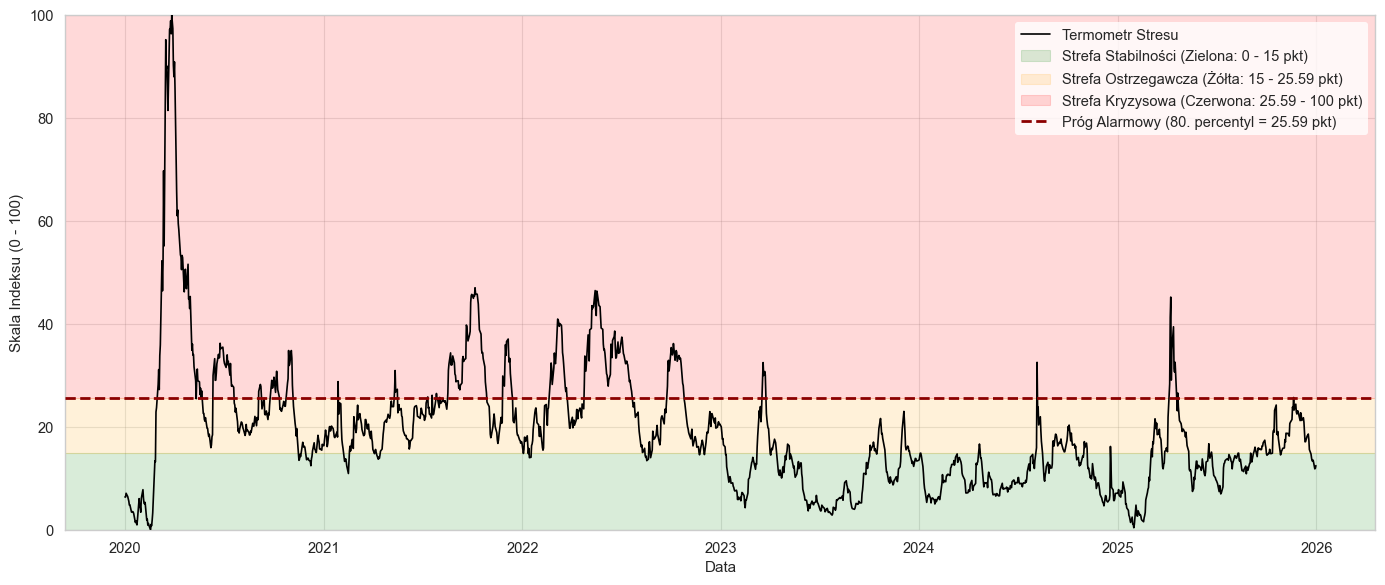

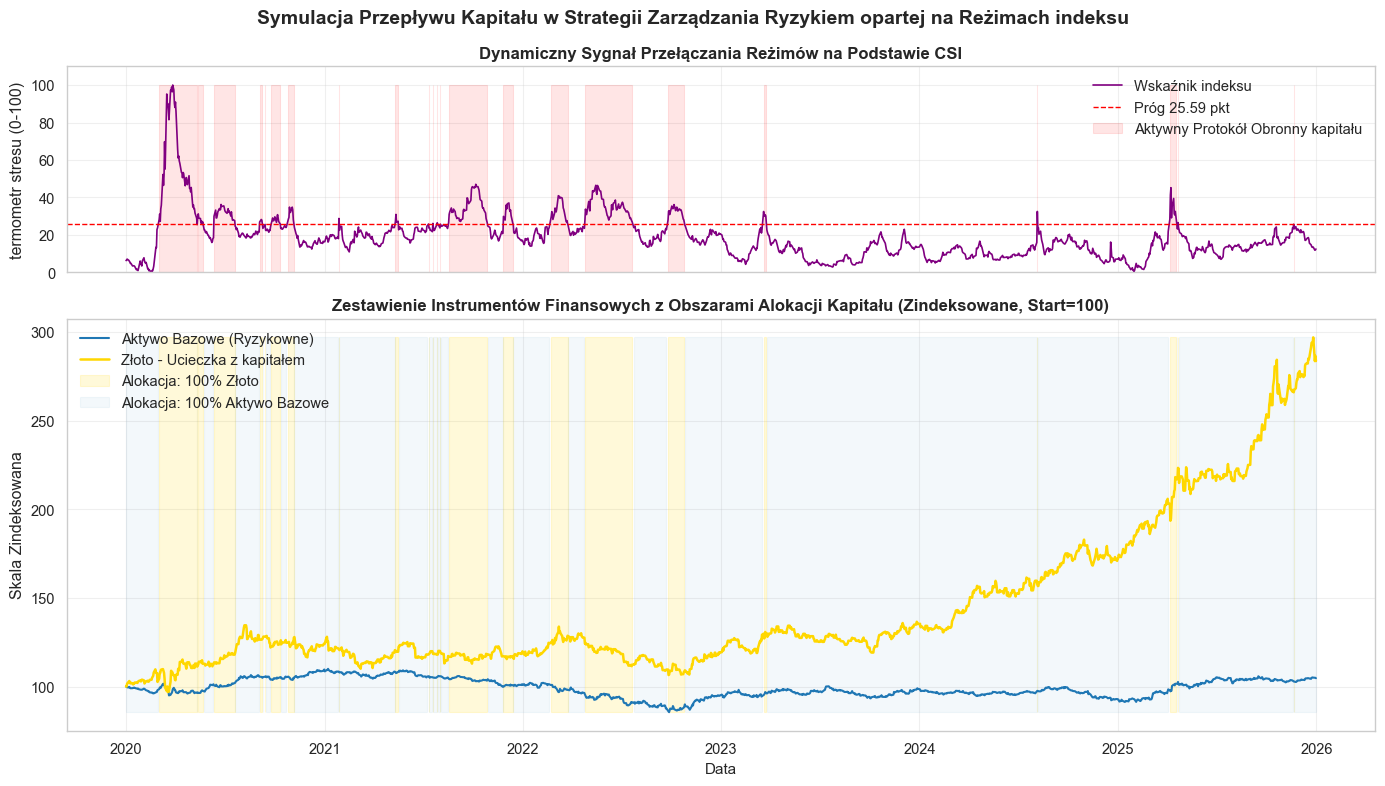

In [5]:
plt.figure(figsize=(14, 6))
plt.plot(df_model['Date'], df_model['CSI'], color='black', lw=1.2, label='Termometr Stresu', zorder=4)

# Progi interpretacyjne
plt.axhspan(0, 15, color='green', alpha=0.15, label='Strefa Stabilności (Zielona: 0 - 15 pkt)')
plt.axhspan(15, 25.59, color='orange', alpha=0.15, label='Strefa Ostrzegawcza (Żółta: 15 - 25.59 pkt)')
plt.axhspan(25.59, 100, color='red', alpha=0.15, label='Strefa Kryzysowa (Czerwona: 25.59 - 100 pkt)')
plt.axhline(y=25.59, color='darkred', linestyle='--', lw=2, label='Próg Alarmowy (80. percentyl = 25.59 pkt)', zorder=5)

plt.xlabel('Data', fontsize=11)
plt.ylabel('Skala Indeksu (0 - 100)', fontsize=11)
plt.ylim(0, 100)
plt.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')
plt.grid(True, alpha=0.2, color='gray')
plt.tight_layout()
plt.show()

# Wykres alokacji kapitalu wg rezimow CSI
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [1, 2]})

ax1.plot(df_model['Date'], df_model['CSI'], color='purple', lw=1.2, label='Wskaźnik indeksu')
ax1.axhline(y=25.59, color='red', linestyle='--', lw=1, label='Próg 25.59 pkt')
ax1.fill_between(df_model['Date'], 0, 100, where=(df_model['Target_Regime'] == 1), color='red', alpha=0.1, label='Aktywny Protokół Obronny kapitału')
ax1.set_title('Dynamiczny Sygnał Przełączania Reżimów na Podstawie CSI', fontsize=12, fontweight='bold')
ax1.set_ylabel('Termometr stresu (0-100)')
ax1.set_ylim(0, df_model['CSI'].max() * 1.1)
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

target_asset_norm = (df_model['Target_Asset_Close'] / df_model['Target_Asset_Close'].iloc[0]) * 100
gold_norm = (df_model['Safe_Haven_Metal_Close'] / df_model['Safe_Haven_Metal_Close'].iloc[0]) * 100

ax2.plot(df_model['Date'], target_asset_norm, color='tab:blue', lw=1.5, label='Aktywo Bazowe (Ryzykowne)')
ax2.plot(df_model['Date'], gold_norm, color='gold', lw=1.8, label='Złoto - Ucieczka z kapitałem')

ax2.fill_between(df_model['Date'], min(target_asset_norm.min(), gold_norm.min()), max(target_asset_norm.max(), gold_norm.max()),
                 where=(df_model['Target_Regime'] == 1), color='gold', alpha=0.15, label='Alokacja: 100% Złoto')
ax2.fill_between(df_model['Date'], min(target_asset_norm.min(), gold_norm.min()), max(target_asset_norm.max(), gold_norm.max()),
                 where=(df_model['Target_Regime'] == 0), color='tab:blue', alpha=0.05, label='Alokacja: 100% Aktywo Bazowe')

ax2.set_title('Zestawienie Instrumentów Finansowych z Obszarami Alokacji Kapitału (Zindeksowane, Start=100)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Data', fontsize=11)
ax2.set_ylabel('Skala Zindeksowana')
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)

plt.suptitle('Symulacja Przepływu Kapitału w Strategii Zarządzania Ryzykiem opartej na Reżimach indeksu', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


=== RAPORT KOŃCOWY BACKTESTINGU (Z UWZGLĘDNIENIEM KOSZTÓW 0.1%) ===
Kapitał początkowy: 100,000.00
Końcowy kapitał Buy & Hold: 104,691.87 (Stopa zwrotu: 4.69%)
Końcowy kapitał Strategii CSI: 117,456.58 (Stopa zwrotu: 17.46%)
Łączna liczba wymuszonych transakcji rynkowych: 46


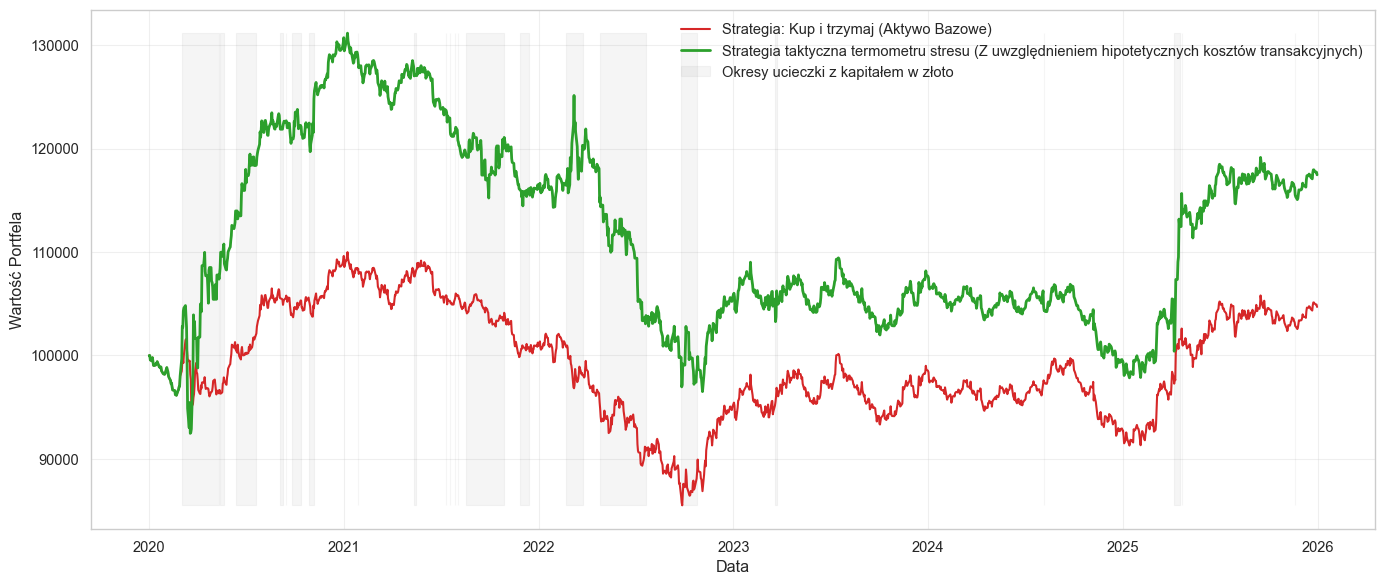

In [6]:
df_model['Asset_Return'] = df_model['Target_Asset_Close'].pct_change().fillna(0)
df_model['Gold_Return'] = df_model['Safe_Haven_Metal_Close'].pct_change().fillna(0)

KAPITAL_STARTOWY = 100000.0
PROWIZJA_MAKLERSKA = 0.001

kapital_buy_hold = [KAPITAL_STARTOWY]
kapital_strategia = [KAPITAL_STARTOWY]

aktualna_pozycja = df_model['Target_Regime'].iloc[0]

for i in range(1, len(df_model)):
    # Strategia pasywna (Kup i trzymaj)
    nowy_kapital_bh = kapital_buy_hold[-1] * (1 + df_model['Asset_Return'].iloc[i])
    kapital_buy_hold.append(nowy_kapital_bh)

    # Strategia taktyczna CSI
    sygnal_na_dzis = df_model['Target_Regime'].iloc[i]
    baza_kapitalu = kapital_strategia[-1]

    if sygnal_na_dzis != aktualna_pozycja:
        baza_kapitalu = baza_kapitalu * (1 - PROWIZJA_MAKLERSKA)
        aktualna_pozycja = sygnal_na_dzis

    if aktualna_pozycja == 0:
        nowy_kapital_strat = baza_kapitalu * (1 + df_model['Asset_Return'].iloc[i])
    else:
        nowy_kapital_strat = baza_kapitalu * (1 + df_model['Gold_Return'].iloc[i])

    kapital_strategia.append(nowy_kapital_strat)

df_model['Kapital_Buy_Hold'] = kapital_buy_hold
df_model['Kapital_Strategia_CSI'] = kapital_strategia

koncowy_bh = df_model['Kapital_Buy_Hold'].iloc[-1]
koncowy_strat = df_model['Kapital_Strategia_CSI'].iloc[-1]
liczba_transakcji = df_model['Target_Regime'].diff().abs().sum()

print("Wyniki symulacji historycznej (prowizja 0.1%):")
print(f"Kapitał początkowy: {KAPITAL_STARTOWY:,.2f}")
print(f"Końcowy kapitał Buy & Hold: {koncowy_bh:,.2f} (Stopa zwrotu: {((koncowy_bh/KAPITAL_STARTOWY)-1)*100:.2f}%)")
print(f"Końcowy kapitał Strategii CSI: {koncowy_strat:,.2f} (Stopa zwrotu: {((koncowy_strat/KAPITAL_STARTOWY)-1)*100:.2f}%)")
print(f"Liczba transakcji: {int(liczba_transakcji)}")

plt.figure(figsize=(14, 6))
plt.plot(df_model['Date'], df_model['Kapital_Buy_Hold'], label='Strategia: Kup i trzymaj (Aktywo Bazowe)', color='tab:red', lw=1.5)
plt.plot(df_model['Date'], df_model['Kapital_Strategia_CSI'], label='Strategia taktyczna termometru stresu (Z uwzględnieniem hipotetycznych kosztów transakcyjnych)', color='tab:green', lw=2)

plt.fill_between(df_model['Date'], df_model['Kapital_Buy_Hold'].min(), df_model['Kapital_Strategia_CSI'].max(),
                 where=(df_model['Target_Regime'] == 1), color='gray', alpha=0.08, label='Okresy ucieczki z kapitałem w złoto')

plt.xlabel('Data')
plt.ylabel('Wartość Portfela')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Kapitał końcowy strategii pasywnej: 104,691.87 PLN

 Percentyl Prog_Punktowy Kapital_Koncowy_PLN  Liczba_Transakcji Przewaga_nad_BH_PLN
        50         16.92      153,056.49 PLN                 80       48,364.62 PLN
        55         18.08      159,553.45 PLN                 68       54,861.58 PLN
        60         19.11      140,362.12 PLN                 76       35,670.25 PLN
        65         20.57      129,674.00 PLN                 70       24,982.13 PLN
        70         21.83      120,972.43 PLN                 80       16,280.57 PLN
        75         23.40      115,204.81 PLN                 72       10,512.94 PLN
        80         25.59      120,746.04 PLN                 44       16,054.17 PLN
        85         29.67      112,549.74 PLN                 42        7,857.87 PLN
        90         33.36      105,421.66 PLN                 44          729.79 PLN
        95         38.95      110,682.13 PLN                 14        5,990.27 PLN


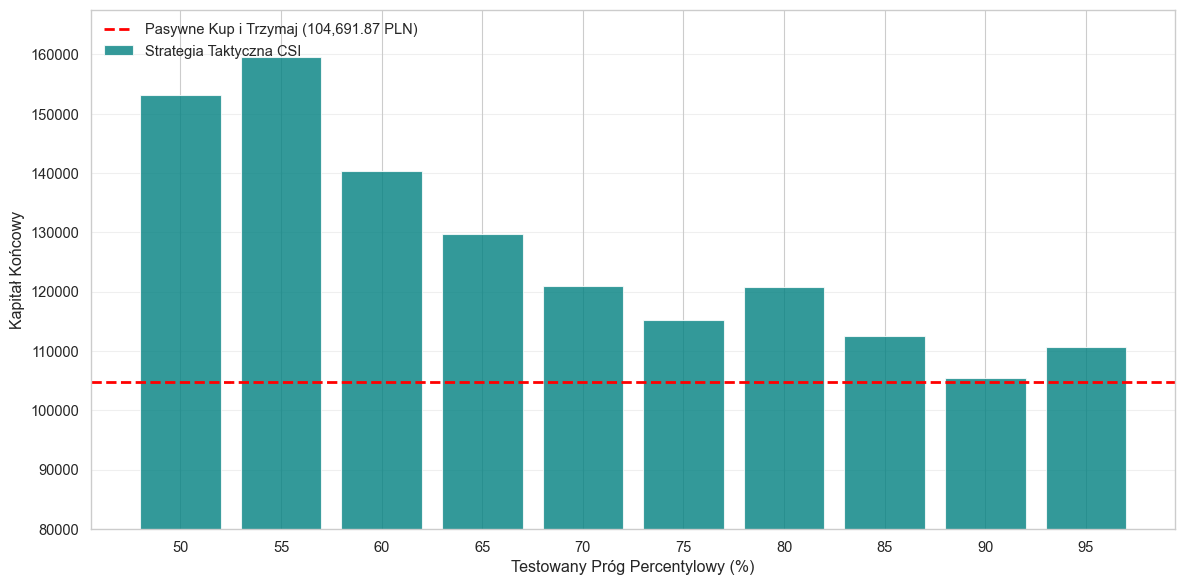

In [7]:
# Analiza wrazliwosci dla progow percentylowych (50% - 95%)
percentiles_to_test = range(50, 96, 5)
prowizja = 0.001
kapital_startowy = 100000

wyniki_wrazliwosci = []

df_test = df_model[['Date', 'CSI', 'Target_Asset_Close', 'Safe_Haven_Metal_Close']].dropna().copy()
df_test = df_test.sort_values('Date').reset_index(drop=True)

df_test['Asset_Return'] = df_test['Target_Asset_Close'].pct_change() + 1
df_test['Safe_Haven_Metal_Return'] = df_test['Safe_Haven_Metal_Close'].pct_change() + 1
df_test = df_test.dropna().reset_index(drop=True)

for pct in percentiles_to_test:
    prog_punktowy = np.percentile(df_test['CSI'], pct)
    df_test['S_t'] = (df_test['CSI'] >= prog_punktowy).astype(int)
    df_test['S_t_lag'] = df_test['S_t'].shift(1).fillna(0)
    df_test['Transakcja'] = df_test['S_t_lag'].diff().fillna(0).abs()

    df_test['Strategia_Return'] = np.where(
        df_test['S_t_lag'] == 1,
        df_test['Safe_Haven_Metal_Return'],
        df_test['Asset_Return']
    )

    df_test['Strategia_Return_Netto'] = df_test['Strategia_Return'] - (df_test['Transakcja'] * prowizja)
    final_equity_CSI = kapital_startowy * df_test['Strategia_Return_Netto'].cumprod().iloc[-1]
    liczba_transakcji = df_test['Transakcja'].sum()

    wyniki_wrazliwosci.append({
        'Percentyl': pct,
        'Prog_Punktowy': prog_punktowy,
        'Kapital_Koncowy_PLN': final_equity_CSI,
        'Liczba_Transakcji': int(liczba_transakcji)
    })

final_equity_BH = kapital_startowy * df_test['Asset_Return'].cumprod().iloc[-1]

df_res = pd.DataFrame(wyniki_wrazliwosci)
df_res['Przewaga_nad_BH_PLN'] = df_res['Kapital_Koncowy_PLN'] - final_equity_BH

print(f"Kapitał końcowy strategii pasywnej: {final_equity_BH:,.2f} PLN\n")
print(df_res.to_string(index=False, formatters={
    'Prog_Punktowy': '{:,.2f}'.format,
    'Kapital_Koncowy_PLN': '{:,.2f} PLN'.format,
    'Przewaga_nad_BH_PLN': '{:,.2f} PLN'.format
}))

plt.figure(figsize=(12, 6))
plt.bar(df_res['Percentyl'].astype(str), df_res['Kapital_Koncowy_PLN'], color='teal', alpha=0.8, label='Strategia Taktyczna CSI')
plt.axhline(final_equity_BH, color='red', linestyle='--', lw=2, label=f'Pasywne Kup i Trzymaj ({final_equity_BH:,.2f} PLN)')

plt.xlabel('Testowany Próg Percentylowy (%)')
plt.ylabel('Kapitał Końcowy')
plt.ylim(bottom=kapital_startowy * 0.8)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()
